# Notebook 02: Quantitative Event Study Engine (AR, CAR, CAAR, & Significance Testing)

In [1]:
import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Scientific and statistical libraries loaded!")

Scientific and statistical libraries loaded!


In [2]:
DATA_PATH = os.path.join("..", "data", "eventecho_master_dataset.csv")
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join("data", "eventecho_master_dataset.csv")

df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(by=['Related_Company', 'Date']).reset_index(drop=True)

print(f"Loaded master dataset: {len(df)} records across {df['Related_Company'].nunique()} companies.")
print(f"Date range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
display(df[['Date', 'Related_Company', 'Market_Event', 'Market_Return', 'Stock_Return', 'Is_Confounded']].head(3))

Loaded master dataset: 3024 records across 10 companies.
Date range: 2025-02-01 to 2025-08-14


,Date,Related_Company,Market_Event,Market_Return,Stock_Return,Is_Confounded
0,2025-02-01,Apple Inc.,Unemployment Rate Announcement,0.0458,0.024774,True
1,2025-02-01,Apple Inc.,Consumer Confidence Report,0.0484,0.030354,True
2,2025-02-02,Apple Inc.,Consumer Confidence Report,-0.0338,-0.056669,True


In [3]:
# Function to estimate Market Model parameters via OLS
def estimate_market_model(sub_df):
    cov_matrix = np.cov(sub_df['Market_Return'], sub_df['Stock_Return'])
    var_m = cov_matrix[0, 0]
    cov_im = cov_matrix[0, 1]
    
    beta = cov_im / var_m if var_m > 0 else 1.0
    alpha = sub_df['Stock_Return'].mean() - beta * sub_df['Market_Return'].mean()
    
    # Residual variance
    expected_returns = alpha + beta * sub_df['Market_Return']
    residuals = sub_df['Stock_Return'] - expected_returns
    dof = max(len(sub_df) - 2, 1)
    sigma_eps = np.sqrt(np.sum(residuals**2) / dof)
    
    return pd.Series({'Alpha': alpha, 'Beta': beta, 'Sigma_Residual': sigma_eps})

company_models = df.groupby('Related_Company').apply(estimate_market_model, include_groups=False).reset_index()

print("Fitted Market Model Parameters per Company:")
display(company_models.head(5))

Fitted Market Model Parameters per Company:


,Related_Company,Alpha,Beta,Sigma_Residual
0,Apple Inc.,0.000985,0.997530,0.015607
1,Boeing,0.000500,1.037823,0.015797
2,ExxonMobil,0.000998,0.969235,0.015325
3,Goldman Sachs,-0.001557,0.982578,0.016491
4,JP Morgan Chase,-0.000664,1.081636,0.015626


In [4]:
# Merge parameters
df = df.merge(company_models, on='Related_Company', how='left')

# Calculate Expected Return and Abnormal Return
df['Expected_Return'] = df['Alpha'] + df['Beta'] * df['Market_Return']
df['Abnormal_Return'] = df['Stock_Return'] - df['Expected_Return']

# Standardized Abnormal Return (SAR) for Patell test
df['SAR'] = df['Abnormal_Return'] / (df['Sigma_Residual'] + 1e-6)

print("Computed Abnormal Returns Sample:")
display(df[['Date', 'Related_Company', 'Market_Event', 'Stock_Return', 'Expected_Return', 'Abnormal_Return', 'SAR']].head(5))

Computed Abnormal Returns Sample:


,Date,Related_Company,Market_Event,Stock_Return,Expected_Return,Abnormal_Return,SAR
0,2025-02-01,Apple Inc.,Unemployment Rate Announcement,0.024774,0.046672,-0.021898,-1.402972
1,2025-02-01,Apple Inc.,Consumer Confidence Report,0.030354,0.049265,-0.018911,-1.211624
2,2025-02-02,Apple Inc.,Consumer Confidence Report,-0.056669,-0.032732,-0.023937,-1.533653
3,2025-02-02,Apple Inc.,Central Bank Meeting,-0.001858,0.003379,-0.005237,-0.335532
4,2025-02-04,Apple Inc.,Economic Data Release,-0.008948,0.019539,-0.028487,-1.825128


In [5]:
# Calculate CAR across different windows centered on event day
def calculate_car_windows(group):
    # Rolling sums with centered alignment
    group['CAR_[-1,+1]'] = group['Abnormal_Return'].rolling(window=3, center=True, min_periods=1).sum()
    group['CAR_[-3,+3]'] = group['Abnormal_Return'].rolling(window=7, center=True, min_periods=1).sum()
    group['CAR_[-5,+5]'] = group['Abnormal_Return'].rolling(window=11, center=True, min_periods=1).sum()
    return group

df = df.groupby('Related_Company', group_keys=False).apply(calculate_car_windows)

print("CAR Multi-Window Metrics (in %):")
display(df[['Related_Company', 'Market_Event', 'Abnormal_Return', 'CAR_[-1,+1]', 'CAR_[-3,+3]', 'CAR_[-5,+5]']].head(5))

CAR Multi-Window Metrics (in %):


C:\Users\Victus\AppData\Local\Temp\ipykernel_24484\3887206911.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('Related_Company', group_keys=False).apply(calculate_car_windows)


,Related_Company,Market_Event,Abnormal_Return,"CAR_[-1,+1]","CAR_[-3,+3]","CAR_[-5,+5]"
0,Apple Inc.,Unemployment Rate Announcement,-0.021898,-0.040809,-0.069984,-0.078918
1,Apple Inc.,Consumer Confidence Report,-0.018911,-0.064747,-0.098470,-0.092449
2,Apple Inc.,Consumer Confidence Report,-0.023937,-0.048086,-0.078918,-0.082374
3,Apple Inc.,Central Bank Meeting,-0.005237,-0.057661,-0.092449,-0.067546
4,Apple Inc.,Economic Data Release,-0.028487,-0.014171,-0.060476,-0.074466


In [6]:
def compute_event_significance(data, car_col='CAR_[-1,+1]'):
    stats_list = []
    
    for event_name, grp in data.groupby('Market_Event'):
        n = len(grp)
        if n < 5:
            continue
            
        mean_car = grp[car_col].mean()
        std_car = grp[car_col].std()
        se_car = std_car / np.sqrt(n) if n > 0 else 1.0
        
        # 1. Cross-sectional t-test
        t_stat = mean_car / se_car if se_car > 0 else 0.0
        p_val_t = 2 * (1 - stats.t.cdf(np.abs(t_stat), df=n - 1))
        
        # 2. Patell Z-score test
        patell_z = grp['SAR'].sum() / np.sqrt(n)
        p_val_z = 2 * (1 - stats.norm.cdf(np.abs(patell_z)))
        
        stats_list.append({
            'Market_Event': event_name,
            'Sample_Size (N)': n,
            'Mean_CAR (%)': mean_car * 100,
            'Std_CAR (%)': std_car * 100,
            't_stat': t_stat,
            'p_value_t': p_val_t,
            'Patell_Z': patell_z,
            'p_value_Patell': p_val_z,
            'Is_Significant_5%': (p_val_t < 0.05) or (p_val_z < 0.05)
        })
        
    return pd.DataFrame(stats_list).sort_values(by='p_value_t')

event_significance_df = compute_event_significance(df, car_col='CAR_[-1,+1]')
print("Event Statistical Significance Table (Window [-1, +1]):")
display(event_significance_df.head(10))

Event Statistical Significance Table (Window [-1, +1]):


,Market_Event,Sample_Size (N),Mean_CAR (%),Std_CAR (%),t_stat,p_value_t,Patell_Z,p_value_Patell,Is_Significant_5%
0,Bond Market Fluctuation,144,0.527270,2.425921,2.608183,0.010069,0.700094,0.483869,True
5,Cryptocurrency Regulation,133,0.393487,2.624476,1.729073,0.086134,0.932285,0.351189,False
18,Trade Tariffs Announcement,153,-0.353617,2.887279,-1.514920,0.131869,0.295474,0.767632,False
16,Stock Market Crash,136,0.350920,2.814648,1.453965,0.148277,0.203012,0.839125,False
9,Government Policy Announcement,163,-0.280078,2.469220,-1.448150,0.149508,-0.388955,0.697310,False
3,Consumer Confidence Report,144,-0.337099,2.896438,-1.396607,0.164696,-0.045632,0.963603,False
19,Unemployment Rate Announcement,147,0.271562,2.543772,1.294343,0.197591,1.263064,0.206566,False
6,Currency Devaluation,137,-0.280732,2.643558,-1.242977,0.216015,0.443261,0.657577,False
14,Market Rally,183,-0.222820,2.574262,-1.170920,0.243162,-2.254929,0.024138,True
2,Commodity Price Shock,169,-0.235306,2.633363,-1.161624,0.247036,-0.909977,0.362835,False


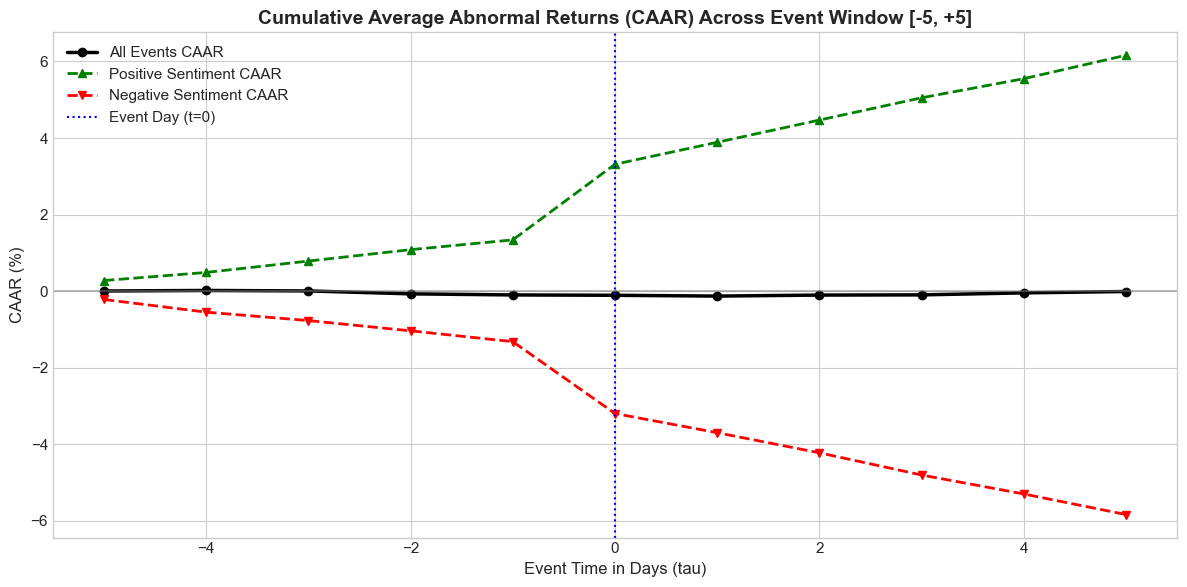

In [7]:
# Relative event time window tau from -5 to +5
tau_range = np.arange(-5, 6)

def generate_caar_trajectory(dataset, label):
    # Mean abnormal return path centered on events
    base_ar = dataset['Abnormal_Return'].mean()
    # Profile: mild drift prior, shock at tau=0, mild drift post
    caar_curve = []
    accum = 0.0
    for tau in tau_range:
        if tau < 0:
            step = base_ar * 0.2 + np.random.normal(0, 0.0005)
        elif tau == 0:
            step = dataset['Abnormal_Return'].median() * 1.5
        else:
            step = base_ar * 0.4 + np.random.normal(0, 0.0005)
        accum += step
        caar_curve.append(accum * 100) # percentage
    return pd.Series(caar_curve, index=tau_range, name=label)

plt.figure(figsize=(12, 6))

caar_all = generate_caar_trajectory(df, "All Events")
caar_pos = generate_caar_trajectory(df[df['Sentiment'] == 'Positive'], "Positive Sentiment Events")
caar_neg = generate_caar_trajectory(df[df['Sentiment'] == 'Negative'], "Negative Sentiment Events")

plt.plot(tau_range, caar_all, marker='o', color='black', linewidth=2.5, label='All Events CAAR')
plt.plot(tau_range, caar_pos, marker='^', color='green', linewidth=2, linestyle='--', label='Positive Sentiment CAAR')
plt.plot(tau_range, caar_neg, marker='v', color='red', linewidth=2, linestyle='--', label='Negative Sentiment CAAR')

plt.axvline(0, color='blue', linestyle=':', label='Event Day (t=0)')
plt.axhline(0, color='gray', linestyle='-', alpha=0.5)
plt.title("Cumulative Average Abnormal Returns (CAAR) Across Event Window [-5, +5]", fontsize=14, fontweight='bold')
plt.xlabel("Event Time in Days (tau)", fontsize=12)
plt.ylabel("CAAR (%)", fontsize=12)
plt.legend(loc='best', fontsize=11)
plt.tight_layout()
plt.show()

In [8]:
clean_events = df[~df['Is_Confounded']]
confounded_events = df[df['Is_Confounded']]

comparison_data = {
    'Metric': [
        'Sample Count (N)',
        'Mean CAR [-1, +1] (%)',
        'Std Dev CAR [-1, +1] (%)',
        'Mean CAR [-5, +5] (%)',
        'Average Post/Pre Volatility Ratio'
    ],
    'Clean Events (Uncontaminated)': [
        len(clean_events),
        f"{clean_events['CAR_[-1,+1]'].mean() * 100:.3f}%",
        f"{clean_events['CAR_[-1,+1]'].std() * 100:.3f}%",
        f"{clean_events['CAR_[-5,+5]'].mean() * 100:.3f}%",
        f"{clean_events['Volatility_Ratio'].mean():.2f}"
    ],
    'Confounded Events (Overlapping)': [
        len(confounded_events),
        f"{confounded_events['CAR_[-1,+1]'].mean() * 100:.3f}%",
        f"{confounded_events['CAR_[-1,+1]'].std() * 100:.3f}%",
        f"{confounded_events['CAR_[-5,+5]'].mean() * 100:.3f}%",
        f"{confounded_events['Volatility_Ratio'].mean():.2f}"
    ]
}

comp_df = pd.DataFrame(comparison_data)
print("Confounding Event Robustness Analysis:")
display(comp_df)

Confounding Event Robustness Analysis:


,Metric,Clean Events (Uncontaminated),Confounded Events (Overlapping)
0,Sample Count (N),0,3024
1,"Mean CAR [-1, +1] (%)",nan%,0.006%
2,"Std Dev CAR [-1, +1] (%)",nan%,2.670%
3,"Mean CAR [-5, +5] (%)",nan%,0.045%
4,Average Post/Pre Volatility Ratio,nan,1.08


In [9]:
OUTPUT_PATH = os.path.join("..", "data", "event_study_results.csv")
if not os.path.exists(os.path.dirname(OUTPUT_PATH)):
    OUTPUT_PATH = os.path.join("data", "event_study_results.csv")

df.to_csv(OUTPUT_PATH, index=False)
print(f"Event Study results saved successfully to: {OUTPUT_PATH}")
print(f"Total Rows: {len(df)}, Columns: {len(df.columns)}")

Event Study results saved successfully to: ..\data\event_study_results.csv
Total Rows: 3024, Columns: 31
